# Sesi 2 — Bagian 2.2: Library untuk Pemrosesan Data

Kita akan menjawab **tiga pertanyaan bisnis** dari dataset penjualan `products.csv`:
1. Produk mana yang paling banyak terjual?
2. Berapa rata-rata harga per kategori?
3. Kategori mana yang stoknya paling rendah?

## Persiapan: install & import library
Aktifkan virtual environment Sesi 1 dulu (atau kita buat environment baru di Sesi 2), lalu jalankan di terminal:
`pip install numpy pandas`

In [3]:
# !pip install numpy pandas

In [2]:
import numpy as np
import pandas as pd

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

## NumPy: kalkulator untuk deret angka

In [3]:
# TODO: buat np.array dari [10, 20, 30] lalu cetak rata-ratanya (.mean())
arr = np.array([10, 20, 30])
print(arr.mean())

20.0


## Load: baca file menjadi DataFrame

In [4]:
# TODO: baca "products.csv" ke dalam df, lalu tampilkan df.head()

df = pd.read_csv("products.csv")
df

,name,category,price,sold,stock
0,Kopi Susu,Beverage,25000,320,45
1,Teh Manis,Beverage,15000,410,60
2,Air Mineral,Beverage,8000,520,120
3,Jus Jeruk,Beverage,22000,180,30
4,Nasi Goreng,Food,30000,275,25
5,Mie Ayam,Food,28000,240,18
6,Ayam Geprek,Food,32000,300,22
7,Roti Bakar,Snack,18000,150,40
8,Kentang Goreng,Snack,20000,210,35
9,Pisang Coklat,Snack,17000,130,12


## Filter: ambil baris yang kita perlukan

In [5]:
# TODO: filter df untuk kategori "Beverage"
beverage_df = df[df['category'] == 'Beverage']

In [6]:
df[df['category'] == 'Snack']

,name,category,price,sold,stock
7,Roti Bakar,Snack,18000,150,40
8,Kentang Goreng,Snack,20000,210,35
9,Pisang Coklat,Snack,17000,130,12
10,Donat,Snack,12000,95,8
11,Croissant,Snack,23000,70,15


---
## Filter dengan Banyak Multiple Condition
Gabungkan kondisi menggunakan `&` (AND) dan `|` (OR), gunakan tanda kurung di tiap kondisi


In [7]:
# TODO: filter Beverage yang harganya di bawah 20000
beverage_df[beverage_df['price'] < 20000]

,name,category,price,sold,stock
1,Teh Manis,Beverage,15000,410,60
2,Air Mineral,Beverage,8000,520,120


---
## Membuat Kolom Baru (Computed Column)
Kita bisa membuat kolom baru berdasarkan nilai dari kolom - kolom yang sudah ada. Contohnya: kita buat kolom `revenue` sebagai hasil perhitungan `harga` × `terjual`.


In [8]:
# TODO: buat kolom baru "revenue" = df["price"] * df["sold"]
df['revenue'] = df['price'] * df['sold'] 

# TODO: tampilkan kolom name, price, sold, revenue pakai df[[...]].head()
df[['name', 'price', 'sold', 'revenue']].head()

,name,price,sold,revenue
0,Kopi Susu,25000,320,8000000
1,Teh Manis,15000,410,6150000
2,Air Mineral,8000,520,4160000
3,Jus Jeruk,22000,180,3960000
4,Nasi Goreng,30000,275,8250000


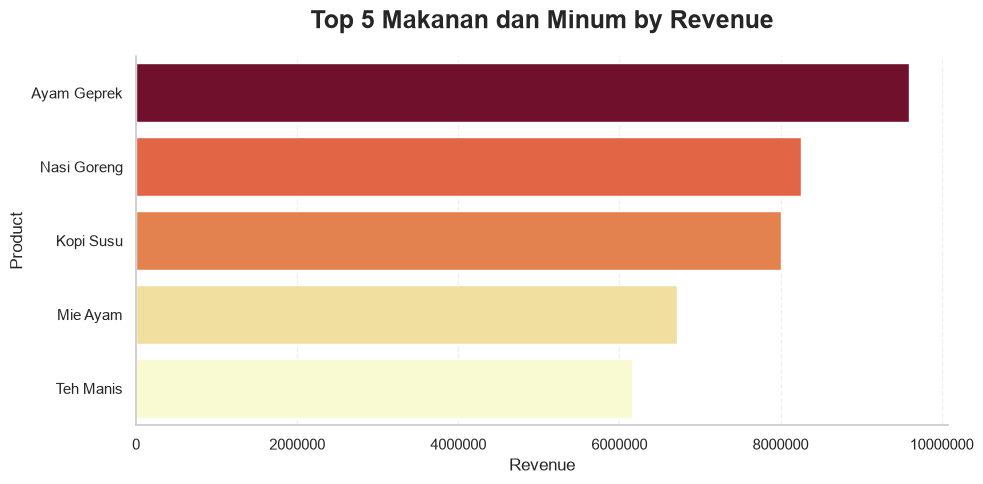

In [28]:
# Mengambil 5 produk dengan revenue tertinggi
top_revenue = df.nlargest(5, 'revenue').sort_values('revenue',
                                                    ascending=False)

# Membuat grafik
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_revenue,
    x='revenue',
    y='name',
    hue='revenue',
    palette='YlOrRd',
    legend=False
)

plt.title('Top 5 Makanan dan Minum by Revenue', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Revenue', fontsize=12)
plt.ylabel('Product', fontsize=12)
plt.ticklabel_format(style='plain', axis='x')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

---
## Urutkan (sort) Beberapa Kolom Sekaligus


In [9]:
# TODO: sort berdasarkan category (ascending) lalu revenue (descending)
df.sort_values(by=['category', 'revenue'], ascending=[True, False])


,name,category,price,sold,stock,revenue
0,Kopi Susu,Beverage,25000,320,45,8000000
1,Teh Manis,Beverage,15000,410,60,6150000
2,Air Mineral,Beverage,8000,520,120,4160000
3,Jus Jeruk,Beverage,22000,180,30,3960000
6,Ayam Geprek,Food,32000,300,22,9600000
4,Nasi Goreng,Food,30000,275,25,8250000
5,Mie Ayam,Food,28000,240,18,6720000
8,Kentang Goreng,Snack,20000,210,35,4200000
7,Roti Bakar,Snack,18000,150,40,2700000
9,Pisang Coklat,Snack,17000,130,12,2210000


---
## value_counts: Hitung Jumlah per Kategori


In [10]:
# TODO: hitung jumlah produk per category pakai .value_counts()
df['category'].value_counts()

category
Snack       5
Beverage    4
Food        3
Name: count, dtype: int64

## Pertanyaan 1 — Produk paling banyak terjual
Urutkan berdasarkan kolom `sold` dari besar ke kecil, ambil teratas.

In [19]:
# TODO: sort_values pada "sold", ascending=False, ambil .head(1)
sold_df = df.sort_values(by='sold', ascending=False)
sold_df.head(1)

,name,category,price,sold,stock,revenue
2,Air Mineral,Beverage,8000,520,120,4160000


## Pertanyaan 2 — Rata-rata harga per kategori
Kelompokkan (`groupby`) berdasarkan kategori, hitung rata-rata harga.

In [20]:
# TODO: groupby "category", ambil kolom "price", hitung .mean()
df.groupby('category')['price'].mean()

category
Beverage    17500.0
Food        30000.0
Snack       18000.0
Name: price, dtype: float64

## Pertanyaan 3 — Kategori dengan stok paling rendah
Jumlahkan stok per kategori, lalu cari yang terkecil.

In [23]:
# TODO: groupby "category", sum kolom "stock",
#       lalu gunakan .idxmin() untuk cari kategori terendah
df.groupby('category')['stock'].sum().idxmin()

'Food'

---
## Simpan DataFrame ke file CSV


In [11]:
# TODO: simpan df ke file "products_analyzed.csv"
# perhatikan: index=False agar kolom index tidak ikut tersimpan
df.to_csv("products_analyze.csv", index=False)
print("Data berhasil disimpan ke products_analyze.csv")


Data berhasil disimpan ke products_analyze.csv
